# Mini-project 4: Rainfall patterns & crop suitability analyser

The twelve monthly totals are **illustrative**, supplied in the brief. Crop bands are simplified monthly heuristics: published requirements are generally **seasonal crop-water demand**, not monthly rainfall requirements. For context, FAO lists roughly 500–800 mm/season for maize and 300–500 mm/season for beans; Uganda's agriculture ministry notes approximately 1,200–1,800 mm across nine months for Arabica coffee. Dividing by illustrative four-, three- and nine-month periods produces a classroom-only monthly screen, not agronomic advice. Sources: [FAO crop water](https://www.fao.org/4/S2022E/s2022e07.htm); [Uganda Ministry of Agriculture coffee manual](https://agriculture.go.ug/wp-content/uploads/2026/01/coffee_manual.pdf).

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
if not (ROOT / "src").exists():
    raise FileNotFoundError("Open Jupyter in the correct folder")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.rainfall import MONTHS, Region, CropRule, compare

regions = [
    Region('Kampala',[120,140,180,200,220,180,90,70,60,100,110,130]),
    Region('Gulu',[8,25,75,160,190,145,170,215,175,150,60,15]),
    Region('Mbarara',[70,85,120,140,90,25,20,55,100,125,120,90])]
crops = [CropRule('maize',125,200), CropRule('beans',100,167),
         CropRule('Arabica coffee',133,200)]
print(pd.DataFrame([{'region':r.name, 'total mm':r.annual_total(), 'mean mm':r.mean(),
                      'wettest':r.wettest(), 'driest':r.driest(), 'CV':r.cv()} for r in regions]
                   ).set_index('region').round(2).to_string())
print('Screening bands, mm/month:', [(c.crop,c.minimum,c.maximum) for c in crops])

         total mm  mean mm wettest driest    CV
region                                         
Kampala    1600.0   133.33     May    Sep  0.39
Gulu       1388.0   115.67     Aug    Jan  0.64
Mbarara    1040.0    86.67     Apr    Jul  0.44
Screening bands, mm/month: [('maize', 125, 200), ('beans', 100, 167), ('Arabica coffee', 133, 200)]


## Monthly moisture screen and comparison matrices

The labels “Drought risk” and “Waterlogging risk” flag a **monthly rainfall band only**. They do not incorporate soil drainage, evapotranspiration, irrigation, crop stage or multi-month accumulated water. A high rainfall month does not by itself establish waterlogging. The cosine similarity formula is (a · b)/(|a| |b|), verified against SciPy's cosine **distance** after conversion `1 − distance`.

In [2]:
for region in regions:
    table = pd.DataFrame({'month':MONTHS, 'rainfall (mm)':region.rainfall})
    for crop in crops:
        table[crop.crop] = [crop.classify(value) for value in region.rainfall]
    print('\n', region.name, 'monthly screen:')
    print(table.to_string(index=False))

names = [r.name for r in regions]
measures = {'cosine':pd.DataFrame(index=names,columns=names,dtype=float),
            'pearson':pd.DataFrame(index=names,columns=names,dtype=float),
            'euclidean_mm':pd.DataFrame(index=names,columns=names,dtype=float)}
for a in regions:
    for b in regions:
        values = compare(a,b)
        # SciPy returns cosine DISTANCE, so the module converts it to similarity.
        assert np.isclose(values['cosine'], values['scipy_cosine'])
        for metric in measures:
            measures[metric].loc[a.name,b.name] = values[metric]
for metric, matrix in measures.items():
    print('\n', metric, '(Euclidean in mm):\n', matrix.round(3).to_string())
print('Cosine measures monthly SHAPE, so multiplying all rainfall by a constant leaves it unchanged; Euclidean distance changes.')


 Kampala monthly screen:
month  rainfall (mm)             maize             beans    Arabica coffee
  Jan          120.0      Drought risk          Suitable      Drought risk
  Feb          140.0          Suitable          Suitable          Suitable
  Mar          180.0          Suitable Waterlogging risk          Suitable
  Apr          200.0          Suitable Waterlogging risk          Suitable
  May          220.0 Waterlogging risk Waterlogging risk Waterlogging risk
  Jun          180.0          Suitable Waterlogging risk          Suitable
  Jul           90.0      Drought risk      Drought risk      Drought risk
  Aug           70.0      Drought risk      Drought risk      Drought risk
  Sep           60.0      Drought risk      Drought risk      Drought risk
  Oct          100.0      Drought risk          Suitable      Drought risk
  Nov          110.0      Drought risk          Suitable      Drought risk
  Dec          130.0          Suitable          Suitable      Drought risk

## Circular seasonal peaks and visualisation

`find_peaks` is applied to December–January wrapped data with a 25 mm prominence rule; one detected peak is labelled “unimodal” and two or more “bimodal”. This is a descriptive rule for **one illustrative year**, not a robust climatological classification. The example Kampala series may show fewer peaks than the familiar southern Uganda two-rainy-season pattern. Gulu's two shoulders are consistent with a [Ugandan ministry district description](https://www.agriculture.go.ug/wp-content/uploads/2022/10/Draft-UCSATP-Environment-Social-Management-Framework.pdf) that describes two peaks around April–May and August–October, although broader northern zones can have one extended rainy season. Replace the figures with multi-year local records before advising farmers.

Kampala peak months: ['May'] illustrative label: unimodal
Gulu peak months: ['May', 'Aug'] illustrative label: bimodal
Mbarara peak months: ['Apr', 'Oct'] illustrative label: bimodal


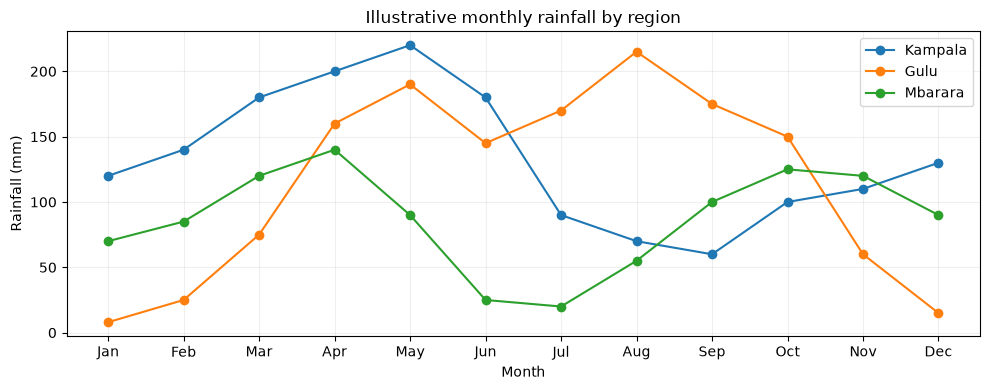

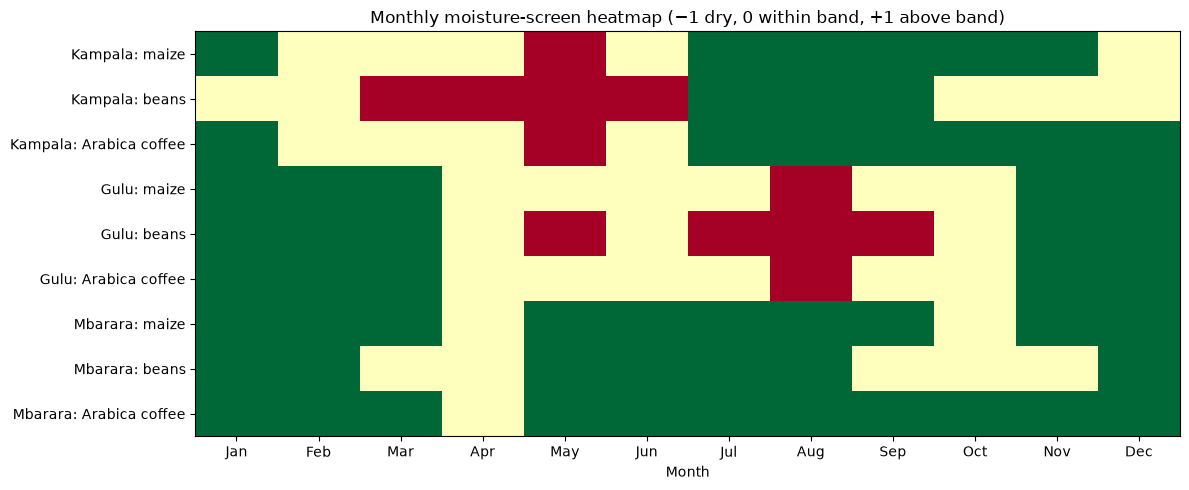

In [3]:
for region in regions:
    peaks = region.rainy_peaks(prominence=25)
    label = 'bimodal' if len(peaks)>=2 else ('unimodal' if len(peaks)==1 else 'unclear')
    print(region.name, 'peak months:', [MONTHS[p] for p in peaks], 'illustrative label:', label)

fig, ax = plt.subplots(figsize=(10,4))
for region in regions:
    ax.plot(MONTHS,region.rainfall,'o-',label=region.name)
ax.set(xlabel='Month',ylabel='Rainfall (mm)',title='Illustrative monthly rainfall by region')
ax.legend()
ax.grid(alpha=.2)
fig.tight_layout()
plt.show()

# Heatmap has a distinct row for every crop/region combination.
labels, image_values = [], []
score = {'Drought risk':-1,'Suitable':0,'Waterlogging risk':1}
for region in regions:
    for crop in crops:
        labels.append(f'{region.name}: {crop.crop}')
        image_values.append([score[crop.classify(v)] for v in region.rainfall])
fig, ax = plt.subplots(figsize=(12,5))
ax.imshow(image_values,aspect='auto',cmap='RdYlGn_r',vmin=-1,vmax=1)
ax.set(xticks=range(12),yticks=range(len(labels)),xticklabels=MONTHS,yticklabels=labels,
       xlabel='Month',title='Monthly moisture-screen heatmap (−1 dry, 0 within band, +1 above band)')
fig.tight_layout()
plt.show()

## Note for Mbarara

The Mbarara example has its strongest monthly totals around March–April and September–November, with markedly drier June–July values. For an illustrative beans crop, consider preparing fields as a rainy period becomes established rather than planting on the strength of one month's total alone. Check local short-range forecasts, soil moisture and drainage before sowing, and seek the current district agriculture advisory for planting dates. The monthly screening band in this notebook is only a demonstration; the supplied figures are not measured field rainfall and cannot establish yield, flooding or irrigation needs.

## Findings

Annual totals and means describe overall rainfall supply, while CV shows how unevenly monthly rainfall is distributed. Kampala, Gulu and Mbarara have different seasonal shapes, which the line chart and monthly crop-screen heatmap make visible. The matrices compare three different notions of resemblance: Euclidean distance is sensitive to the amount of rainfall, Pearson correlation compares deviations from each region's average, and cosine similarity compares direction from the zero vector. Thus two regions with the same monthly pattern at very different amounts can have cosine near one, while their Euclidean distance remains large.

Peak detection uses the actual `scipy.signal.find_peaks` function on a December-to-January wrapped sequence, with a stated prominence rule. It provides a repeatable label but its output depends on the threshold. A single synthetic year should not be taken as proof of Uganda's climate zones. In particular, illustrative Kampala may fail to display the expected southern bimodal pattern; Gulu's two detected peaks match one district description but need checking against several measured years from a meteorological source.

FAO water requirements refer to a whole growth period, and the Ugandan coffee guidance spans most of a year. Dividing those values into equal monthly bands is an explicit classroom assumption. Rainfall is not equivalent to crop water available after runoff and evaporation, and high rainfall is not automatically waterlogging. The advisory note must therefore be checked against local soil, crop stage and current forecasts before any farming decision.